<a href="https://colab.research.google.com/github/minhnguyenrun/Do-an-chuyen-nganh-261/blob/xuan/methods/chandra/notebooks/chandra_reportcolab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
from google.colab import userdata
token = userdata.get('GH_TOKEN')
!git clone https://github.com/minhnguyenrun/Do-an-chuyen-nganh-261.git

Cloning into 'Do-an-chuyen-nganh-261'...
remote: Enumerating objects: 468, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 468 (delta 1), reused 5 (delta 1), pack-reused 455 (from 1)
Receiving objects: 100% (468/468), 44.02 MiB | 13.99 MiB/s, done.
Resolving deltas: 100% (139/139), done.


In [12]:
%cd /content/Do-an-chuyen-nganh-261

# 1. Fetch và chuyển sang nhánh xuan
!git fetch origin xuan
!git checkout xuan

# 2. Kéo code mới nhất về
!git pull origin xuan

# 3. Kiểm tra xem đã nhận đúng commit mới nhất chưa
!git log -1 --oneline

/content/Do-an-chuyen-nganh-261
remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Total 5 (delta 4), reused 5 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 983 bytes | 983.00 KiB/s, done.
From https://github.com/minhnguyenrun/Do-an-chuyen-nganh-261
 * branch            xuan       -> FETCH_HEAD
   9dbc1b5..6e43334  xuan       -> origin/xuan
Already on 'xuan'
Your branch is behind 'origin/xuan' by 1 commit, and can be fast-forwarded.
  (use "git pull" to update your local branch)
From https://github.com/minhnguyenrun/Do-an-chuyen-nganh-261
 * branch            xuan       -> FETCH_HEAD
Updating 9dbc1b5..6e43334
Fast-forward
 scripts/download_datasets/download_doclaynet.py | 51 +++++++++++++++----------
 1 file changed, 31 insertions(+), 20 deletions(-)
6e43334 (HEAD -> xuan, origin/xuan) feat: add --splits and --output-dataset options to download_doclaynet.py


In [13]:
%cd /content/Do-an-chuyen-nganh-261
!pip install -r methods/chandra/requirements.txt
!pip install pycocotools

/content/Do-an-chuyen-nganh-261


In [14]:
# Tải khoảng 20-50 ảnh để thử nghiệm nhanh
!python scripts/download_datasets/download_doclaynet.py --splits test --max-images 20 --delete-raw

[download] data/test-00000-of-00006.parquet (515 MB)

data/test-00000-of-00006.parquet: downloading bytes:  36% 187M/515M [00:02<00:01, 184MB/s, 11.3MB/s  ]
data/test-00000-of-00006.parquet: downloading bytes:  48% 247M/515M [00:02<00:01, 216MB/s, 21.6MB/s  ]
data/test-00000-of-00006.parquet: reconstructing file:  24% 122M/515M [00:02<00:07, 54.1MB/s, 6.36MB/s  ]
data/test-00000-of-00006.parquet: reconstructing file:  36% 188M/515M [00:02<00:03, 96.8MB/s, 11.3MB/s  ]
data/test-00000-of-00006.parquet: downloading bytes:  95% 489M/515M [00:03<00:00, 220MB/s, 41.3MB/s  ]
data/test-00000-of-00006.parquet: reconstructing file:  85% 438M/515M [00:03<00:00, 169MB/s, 24.9MB/s  ]
data/test-00000-of-00006.parquet: downloading bytes: 100% 503M/503M [00:04<00:00, 120MB/s, 42.8MB/s  ]
data/test-00000-of-00006.parquet: reconstructing file: 100% 515M/515M [00:04<00:00, 123MB/s, 44.2MB/s  ]
[download] data/test-00001-of-00006.parquet (434 MB)

data/test-00001-of-00006.parquet: downloading bytes:  83% 

In [21]:
!python methods/chandra/src/run_inference.py --dataset doclaynet --limit 5 --force

[chandra] 5 image(s) to predict from /content/Do-an-chuyen-nganh-261/datasets/doclaynet/processed/images (device: cuda) (force overwrite)
[chandra] Chưa tìm thấy trọng số đầy đủ tại: /content/Do-an-chuyen-nganh-261/methods/chandra/weights
[chandra] Đang chuẩn bị tải từ Hugging Face Hub: datalab-to/chandra-ocr-2...
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 17 files:   0% 0/17 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/2.77k [00:00<?, ?B/s]         

Fetching 17 files:   6% 1/17 [00:00<00:04,  3.64it/s]Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.

Reconstructing (incomplete total...):  31% 2.77k/8.94k [00:00<00:00, 10.1kB/s]
Reconstructing (incomplete total...):  85% 8.94k/10.6k [00:00<00:00, 10.1kB/s]
Reconstructing (incomplete total...):  49% 10.6k/21.8k [00:00<00:01, 10.1kB/s]
Reconstructing (incomplete total...):  60% 21.8k/

In [25]:
!python scripts/evaluate_predictions.py \
    --method chandra \
    --dataset doclaynet \
    --split test \
    --allow-incomplete \
    --loose \
    --plot outputs/reports/chandra_doclaynet/metrics_chart.png

Evaluation: chandra on doclaynet/test | 5 images | GT=67 boxes | Predictions=70 boxes | IoU >= 0.5

=== Strict (location and class) ===
Micro: Precision=0.557  Recall=0.582  F1=0.569  TP=39 FP=31 FN=28  mean IoU=0.816
Macro (mean across 8 ground-truth classes): Precision=0.422  Recall=0.433  F1=0.416
Class                   GT    Pred     TP     FP     FN     Prec   Recall       F1
Text                    37      40     25     15     12    0.625    0.676    0.649
Section-header           9      13      6      7      3    0.462    0.667    0.545
Table                    8       5      5      0      3    1.000    0.625    0.769
Page-footer              5       3      0      3      5    0.000    0.000    0.000
Picture                  4       7      2      5      2    0.286    0.500    0.364
Page-header              2       1      0      1      2    0.000    0.000    0.000
Caption                  1       0      0      0      1    0.000    0.000    0.000
Footnote                 1       1

In [26]:
!python visualization/scripts/visualize_predictions.py \
    --method chandra \
    --dataset doclaynet \
    --split test \
    --limit 5 \
    --output-dir outputs/reports/chandra_doclaynet_test

[viz] Ve 5 anh (chandra vs ground truth) tu /content/Do-an-chuyen-nganh-261/visualization/scripts/../../outputs/predictions/chandra/doclaynet
  [ok] 1.png
  [ok] 2.png
  [ok] 3.png
  [ok] 4.png
  [ok] 5.png
[viz] Xong. Anh luu tai outputs/reports/chandra_doclaynet_test


Tìm thấy 5 ảnh, đang hiển thị...

Trang tài liệu: 1.png (Bên trái: Ground Truth | Bên phải: Chandra)


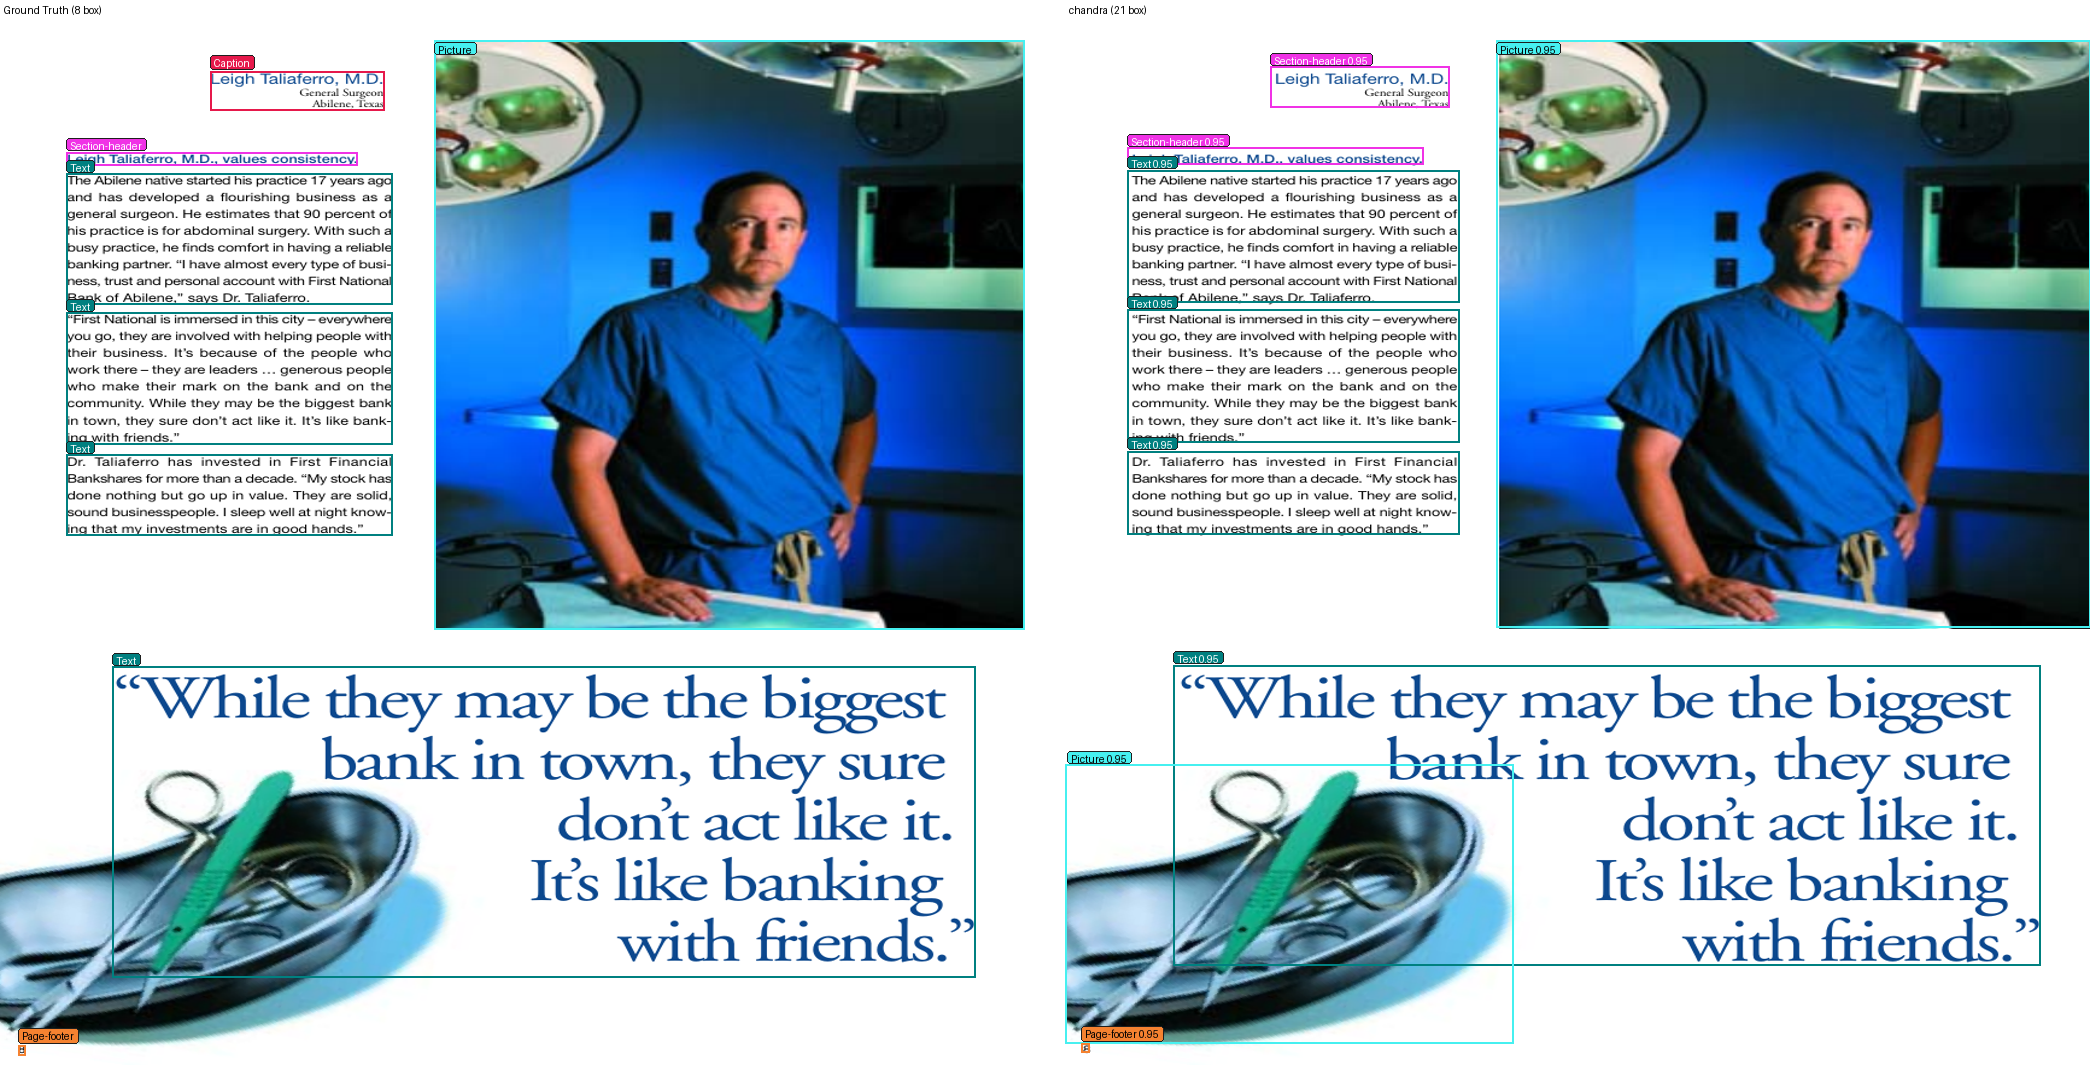

Trang tài liệu: 2.png (Bên trái: Ground Truth | Bên phải: Chandra)


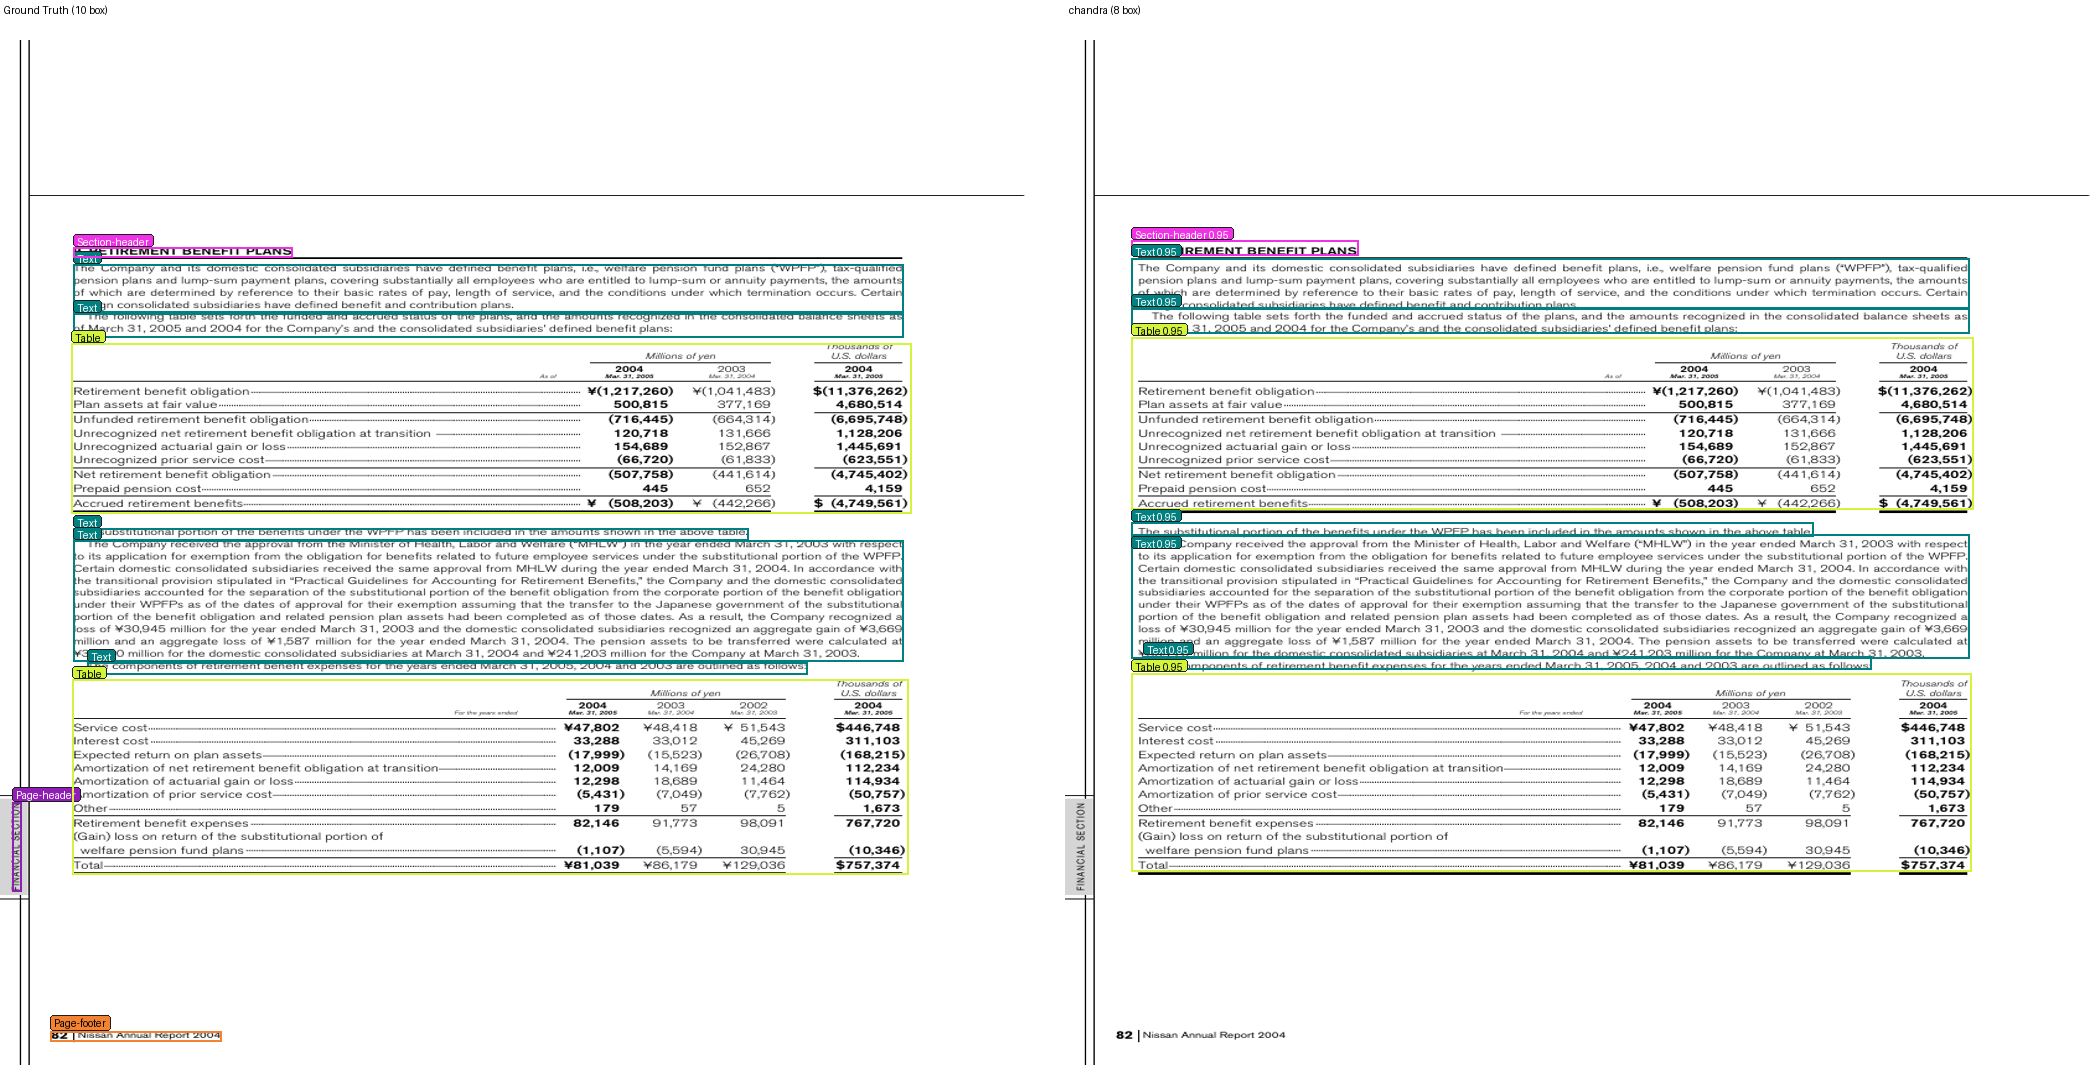

Trang tài liệu: 3.png (Bên trái: Ground Truth | Bên phải: Chandra)


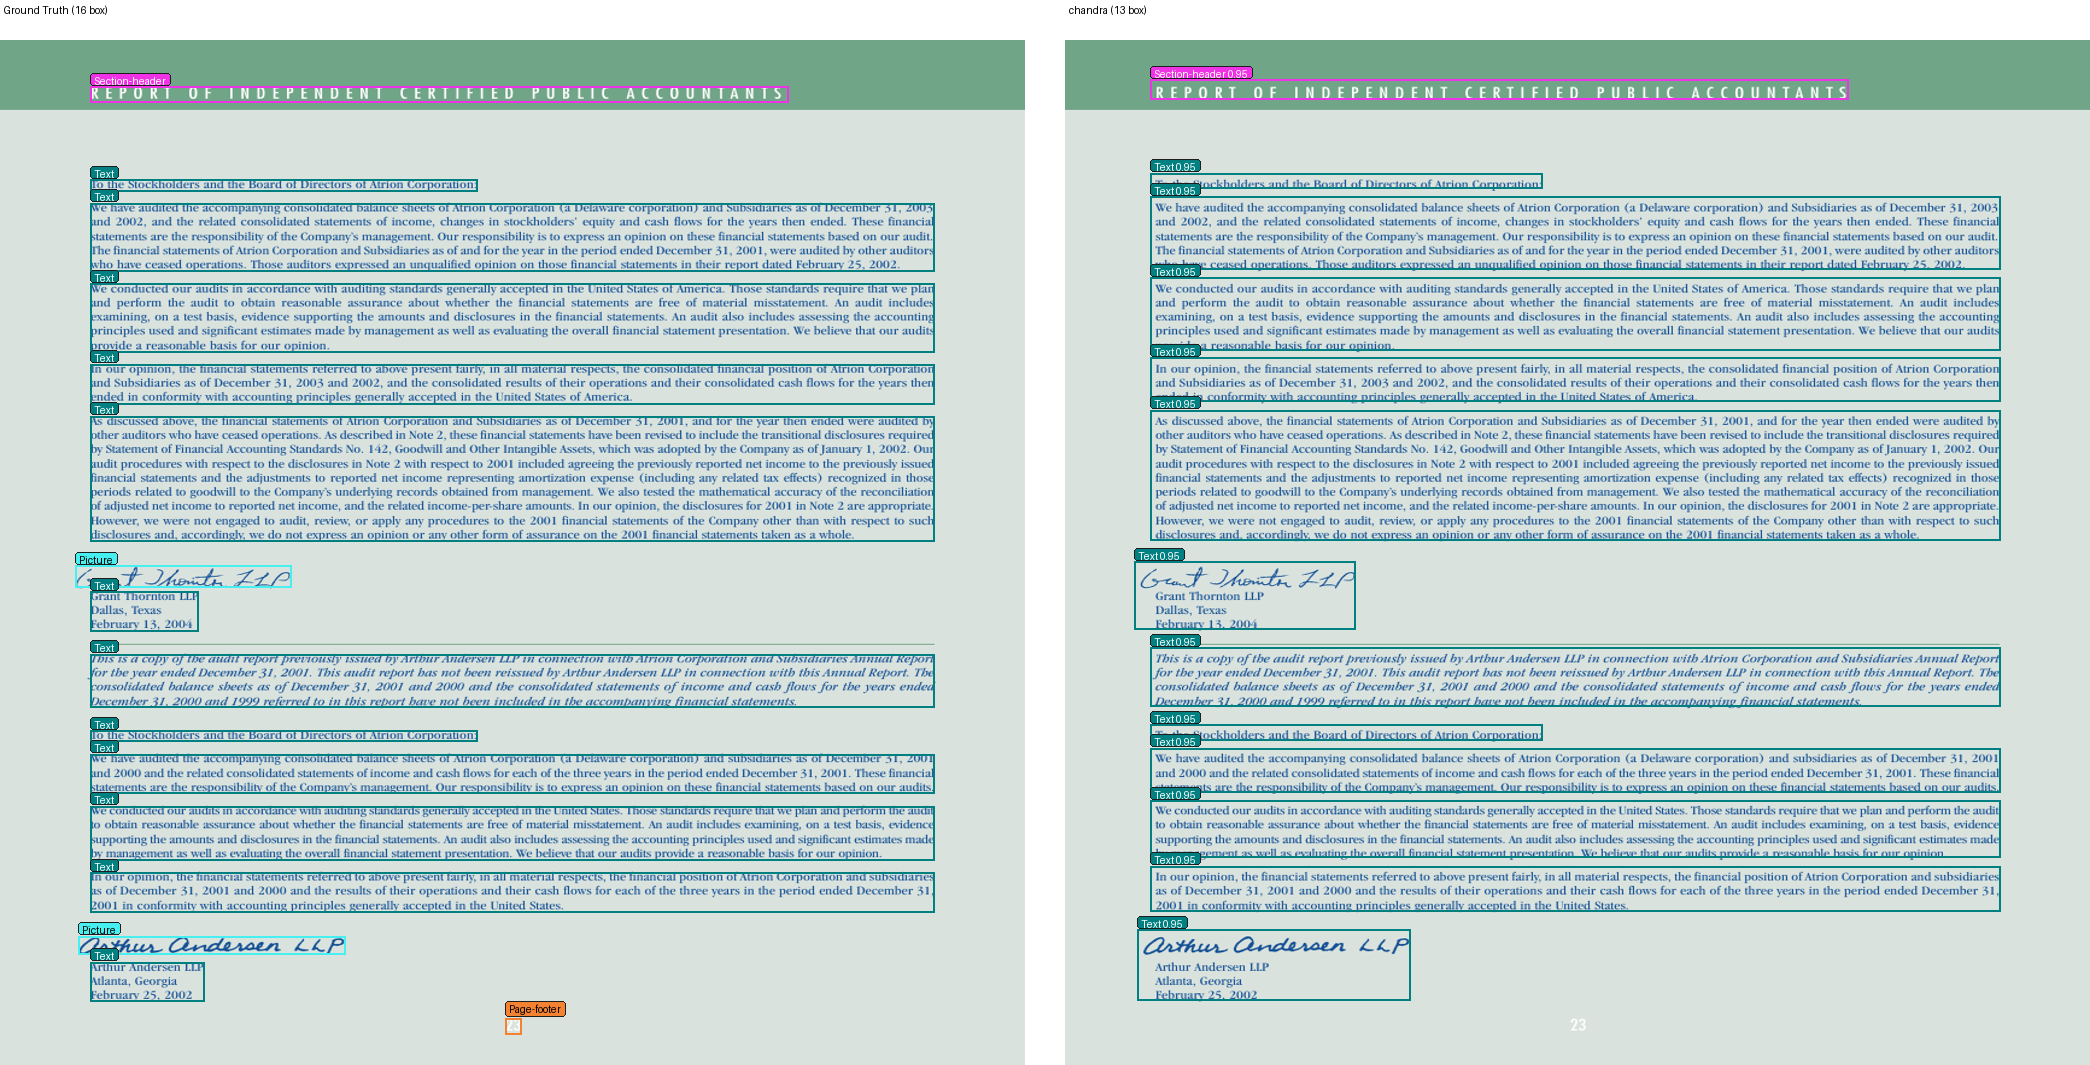

Trang tài liệu: 4.png (Bên trái: Ground Truth | Bên phải: Chandra)


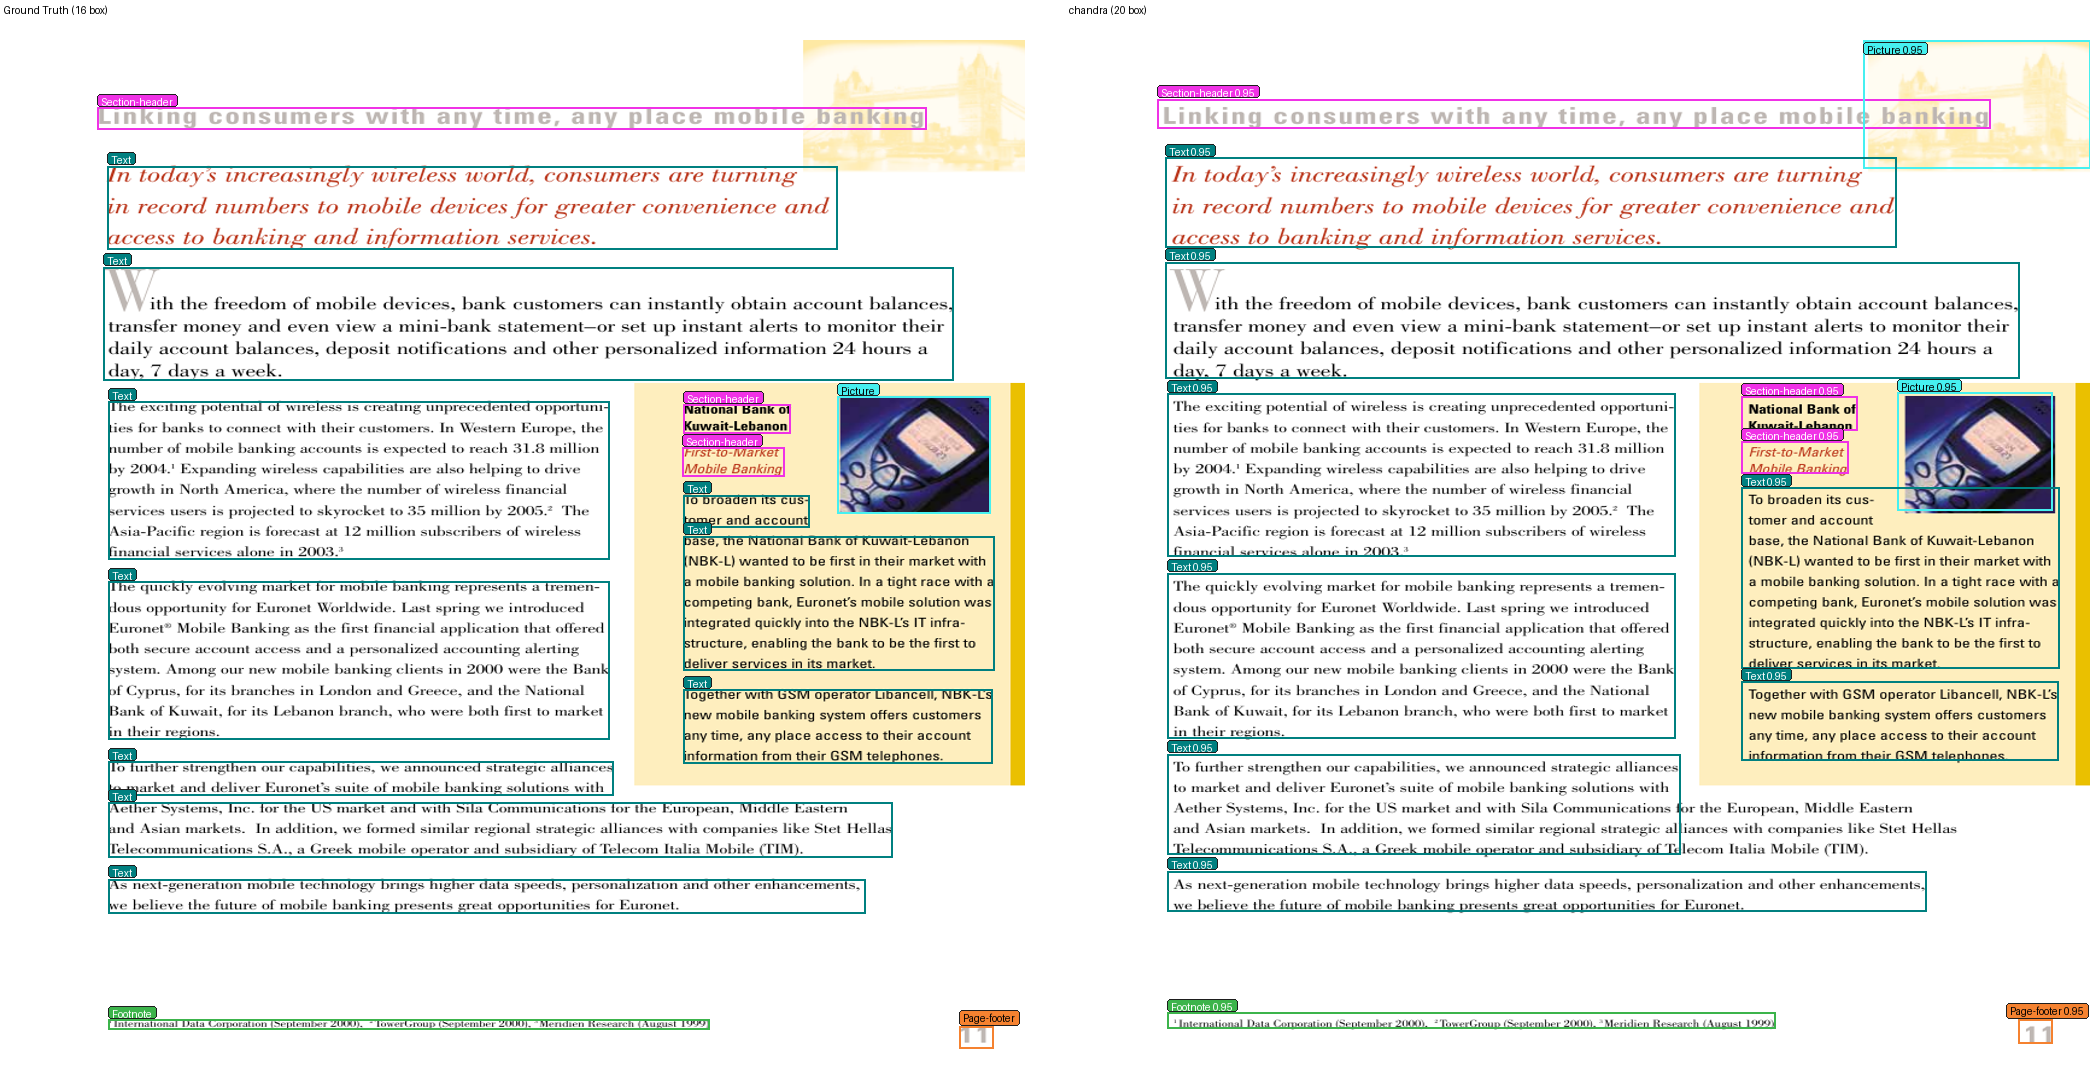

Trang tài liệu: 5.png (Bên trái: Ground Truth | Bên phải: Chandra)


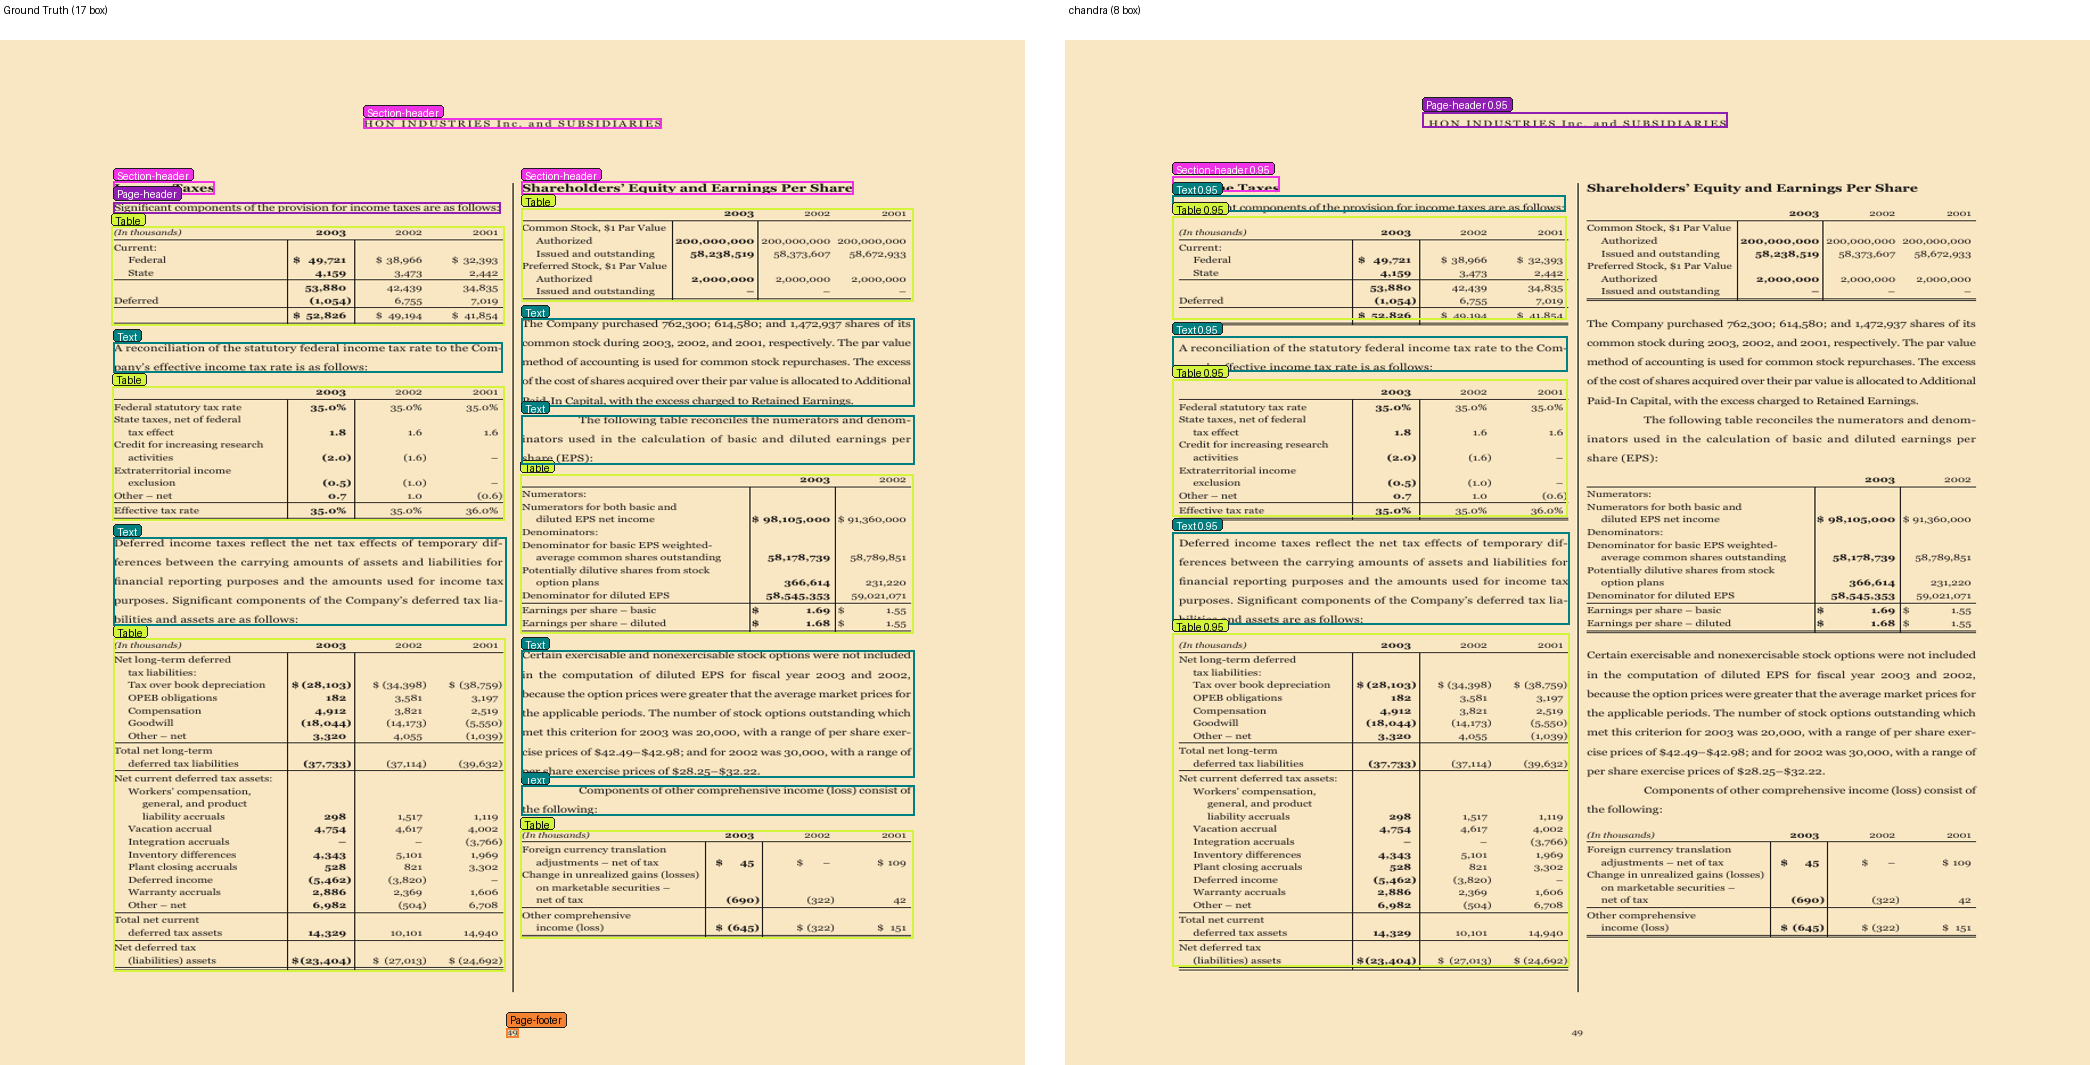

In [27]:
from pathlib import Path
from IPython.display import Image, display

# Đường dẫn thư mục chứa ảnh vừa vẽ
report_dir = Path("outputs/reports/chandra_doclaynet_test")
images = sorted(
    report_dir.glob("*.png"),
    key=lambda p: (0, int(p.stem)) if p.stem.isdigit() else (1, p.stem)
)

print(f"Tìm thấy {len(images)} ảnh, đang hiển thị...\n")

for img_path in images:
    if img_path.name == "metrics_chart.png":
        continue
    print(f"==================================================")
    print(f"Trang tài liệu: {img_path.name} (Bên trái: Ground Truth | Bên phải: Chandra)")
    print(f"==================================================")
    display(Image(filename=str(img_path), width=1000))